# 16 - Borehole Image (FMI) Processing

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_b_advanced/16_borehole_image_fmi.ipynb)

**Part B - Petrophys Curriculum**

A Fullbore Formation MicroImager (FMI) is not an ordinary scalar log. Instead of one value per
depth, each depth samples the borehole wall with **many microresistivity buttons** spread
across a set of pads and flaps. The raw recording is a strip of *buttons*, not a picture:
its columns are sensor positions on the tool, not compass directions. A recognisable
image only appears once every button is **rotated to its true azimuth** using the tool's
navigation curve and then contrast-enhanced (equalized).

This lesson walks through the `petrophys.interpretation.borehole_imaging` FMI pipeline end to end on a
**real processed FMI** from the **Daydream 1** well (QGC, ATP 645, Bowen Basin,
Queensland) - public well-completion-report data.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml,dlis]"

## Learning goals

- Understand what an FMI records: pads/flaps, buttons, and the `P1AZ` navigation curve.
- Load an image log with `read_fmi_dlis` (its siblings `read_borehole_image_dlis` and
  `read_borehole_image_las` read generic image DLIS and flattened LAS exports) into a
  `BoreholeImageData` container.
- Rotate the buttons to compass azimuth with `orient_to_azimuth` - the step that turns
  a strip into an image.
- Choose **static** or **dynamic** equalization with `plot_fmi(equalize=...)` and know
  when to pick which.
- Measure `azimuthal_coverage` and display with `plot_fmi` /
  `visualization.fmi_panel`.

## Why this matters

FMI images are the primary tool for **structural and sedimentological dip picking**:
a planar bed or fracture that cuts the borehole at an angle projects onto the unrolled
0-360 degree image as a **sinusoid**. The amplitude of that sinusoid encodes dip
magnitude and its trough points down-dip azimuth. None of this is visible in the raw
per-button strip - it emerges only after orientation. Equalization then trades
large-scale contrast against fine textural detail so an interpreter can see both thick
units and thin laminae.

### Prerequisites

This lesson assumes you are comfortable with `pp.read` / `read_las` and the
`Well`/`Curve` model from the Part A foundations lessons. No prior imaging
knowledge is required.

It needs two things beyond the base install:

1. **The DLIS extra.** Image logs are read from DLIS files with `dlisio`:
   `pip install "petrophys[dlis]"`.
2. **The processed Daydream 1 FMI image** (a DLIS file of about 110 MB, public
   Queensland well-completion data). It is too large for the installable
   wheel, so the loading cell downloads it on first use, checks its SHA-256 and
   keeps it for later runs. To use another processed FMI DLIS, set the
   environment variable `PETROPHYS_FMI_DLIS` to its path before you start
   Jupyter.

If either is missing, the loading cell in Section 1 stops with a message that
says which one: an `ImportError` for `dlisio`, or an `OSError` that names the
download address when the file cannot be fetched (no network, or no file at that
address). The cells after it then cannot run; the outputs and figures saved in
this notebook show what they produce on the Daydream 1 image.

In [2]:
import os

import pandas as pd

import petrophys as pp

from petrophys.datasets import integration_fixture
from petrophys.interpretation.borehole_imaging import (
    read_fmi_dlis, get_navigation, orient_to_azimuth, azimuthal_coverage, plot_fmi,
)


## 1. How the readers map onto data sources

`petrophys.interpretation.borehole_imaging` offers three entry points, all returning a `BoreholeImageData`:

| Function | Source | Typical use |
| --- | --- | --- |
| `read_fmi_dlis(path)` | processed FMI DLIS | **preferred** - reads image channels *and* navigation (`P1AZ`, `HAZI`, `DEVI`, `RB`), interpolating nav onto image depth |
| `read_borehole_image_dlis(path)` | any image DLIS frame | generic electrical/acoustic image, auto-detects array channels |
| `read_borehole_image_las(path)` | flattened LAS export | LAS can't hold DLIS arrays, so buttons arrive as `FMPA_0 ... FMPA_23`; this regroups them into a 2D image |

Below we load the Daydream 1 processed FMI with the preferred entry point,
`read_fmi_dlis`; the container summarizes itself: its image channels, the size of the
image (depth rows x buttons) and the depth window. The other two readers follow the same pattern on their own
sources.

In [3]:
# PETROPHYS_FMI_DLIS selects another processed FMI DLIS; otherwise the
# Daydream 1 image is downloaded on first use.
data = read_fmi_dlis(os.environ.get("PETROPHYS_FMI_DLIS")
                     or integration_fixture("daydream1_fmi_processed_dynamic_image.dlis"))
data

BoreholeImageData(fmi_raw, FMPA, FMFA, FMPB, FMFB, FMPC, FMFC, FMPD, FMFD: 500788 depths x 192 samples around the hole, 2869-4141 m)

## 2. Pads, flaps, buttons and navigation

The FMI carries **4 pads** (`FMPA-FMPD`) and **4 flaps** (`FMFA-FMFD`), each with
24 microresistivity buttons: 8 arrays x 24 = **192 columns** in the image, over
500,788 depth rows (2869-4141 m at 2.5 mm sampling). Each array sits at a fixed
azimuthal offset from pad 1 (45 degrees apart, in the order listed above), and the
tool's own compass curve `P1AZ` records where pad 1 points at every depth.
`read_fmi_dlis` loaded the navigation (`P1AZ`, `RB`, `DEVI`, `HAZI`) and
interpolated it onto the image depth grid. `get_navigation` returns it; its
statistics tell the story of the run:

In [4]:
pd.DataFrame(get_navigation(data)).describe().round(1)

,P1AZ,HAZI,DEVI,RB
count,500788.0,500788.0,500788.0,500788.0
mean,153.1,289.7,2.2,180.7
std,93.2,9.2,0.4,92.1
min,0.0,261.3,1.6,0.0
25%,82.3,283.1,2.0,107.4
50%,141.5,290.1,2.1,180.2
75%,220.3,297.7,2.4,245.9
max,360.0,304.2,3.6,360.0


`P1AZ` runs over the full 0-360 degrees: the tool rotates as it is pulled up the
hole. `DEVI` has a median of 2.1 degrees, so the hole is close to vertical, and the
hole azimuth `HAZI` stays near 290 degrees.

### A working window

At 2.5 mm sampling the full log is half a million rows, so we cut a **working
window** with `filter_by_depth` and do everything on the window. Depth filtering
carries the attached navigation along, so a window is always orientable if its
parent was:

In [5]:
zoom = data.filter_by_depth(2900.0, 2910.0)
zoom.image.shape, sorted(get_navigation(zoom))

((3937, 192), ['DEVI', 'HAZI', 'P1AZ', 'RB'])

## 3. The raw strip is not an image

Plot the raw button array as-is. The brown scale is the image-log convention: dark is
conductive, light is resistive. The x-axis is a **borehole sample index**: 192
contiguous button columns in tool order, pad by pad. Notice the vertical seams
where one pad's strip ends and the next begins - each pad looks at a different
part of the wall, so the same bed sits at a slightly different tone and depth in
neighbouring blocks, and as the tool rotates the geology slides between columns.
There is no compass meaning here: dip magnitude and azimuth cannot be read from
this view.

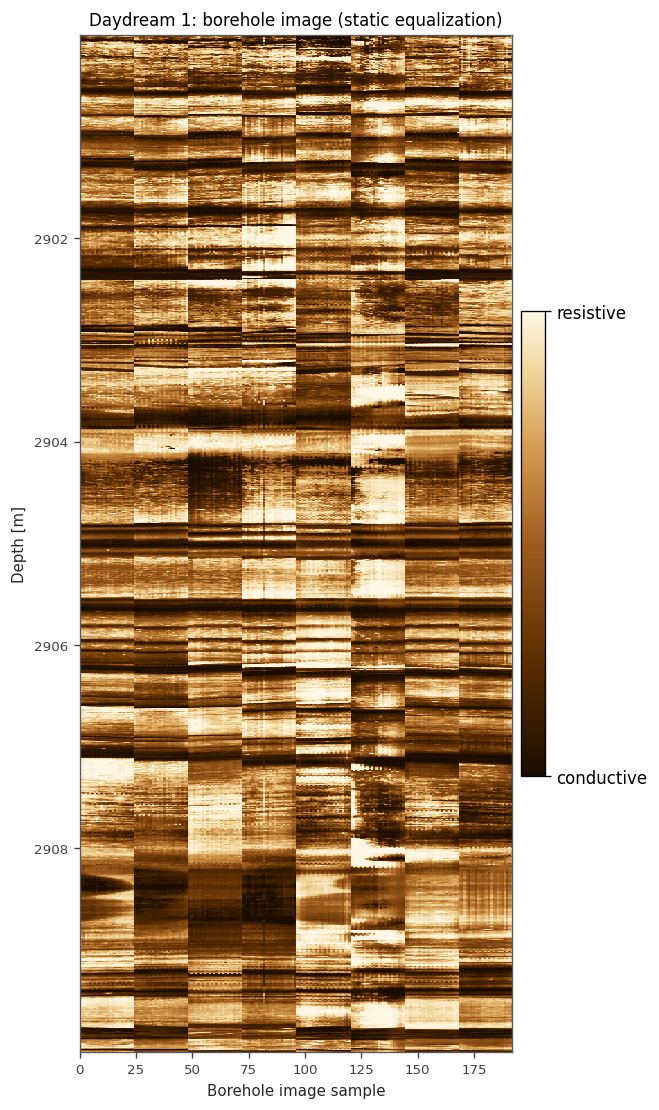

In [6]:
plot_fmi(zoom, equalize="static", interpolation="nearest");

## 4. Orient to azimuth: the key step

`orient_to_azimuth` rotates every button to its true compass azimuth using the
navigation reference (`reference="north"` uses `P1AZ`; `reference="highside"` uses `RB`)
plus each array's fixed offset, then bins the buttons onto a regular 0-360 degree grid.

Crucially, the wedges **between** pads are never imaged, so they are left as `NaN`
(gaps) rather than interpolated - the picture reflects real borehole-wall coverage.
The output is a new `BoreholeImageData` with one column per azimuth bin; its
metadata records the arrays it used.

In [7]:
oriented = orient_to_azimuth(zoom, n_azimuth=180, reference="north")
oriented.image.shape, oriented.metadata["used_arrays"]

((3937, 180), ['FMPA', 'FMFA', 'FMPB', 'FMFB', 'FMPC', 'FMFC', 'FMPD', 'FMFD'])

Plot the oriented image with `plot_fmi`. The x-axis carries a **compass
scale** (N-E-S-W-N): every button sits at its true azimuth, so beds line up
across pads as continuous bands. The white wedges are the un-imaged gaps between
pads - and they **spiral with depth**, because the gaps sit at fixed
positions on the rotating tool, so their compass position drifts as the tool
turns. The image squeezes about 10 m of depth against the whole circumference, several
times the vertical scale of a 1:1 view, which flattens every sinusoid: read dips
on a 1:1 image or with a dip-picking tool, not from this view. A steeply dipping
surface traces a full sinusoid whose trough points down-dip; a feature along the
borehole axis runs down the image at one azimuth. The dark trace near
4055-4058 m (Exercise 1) drifts about 30 degrees in azimuth over those 3 m, beside
the edge of one pad, as the pad gaps do.

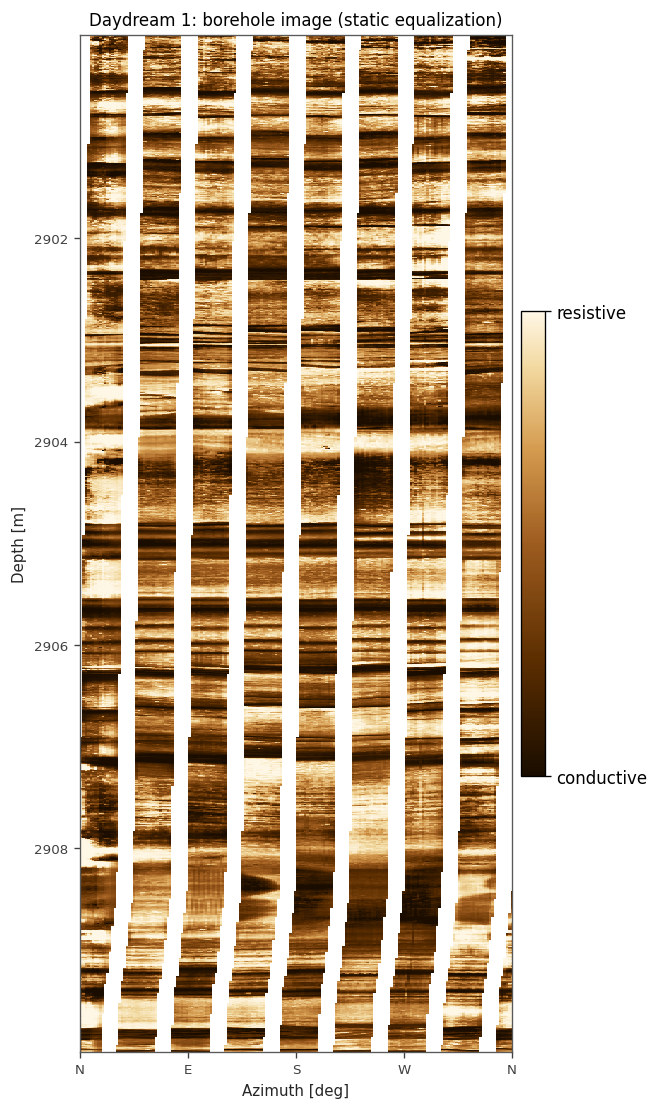

In [8]:
plot_fmi(oriented, equalize="static", interpolation="nearest");

### Azimuthal coverage

`azimuthal_coverage` reports, per depth, the fraction of the 360 degrees
actually imaged - the un-imaged inter-pad wedges are the missing fraction. On
this window Daydream 1 images 70% of the circumference (the mean below). Note
that the library computes coverage from the tool's fixed pad geometry, so it
does not respond to hole enlargement (a washout hurts image *quality* long
before it changes this number).

In [9]:
azimuthal_coverage(oriented).mean().round(2)

np.float64(0.7)

## 5. Static vs dynamic equalization

The industry-standard FMI presentation is a **dual display**: a **static**
image (one percentile stretch over the whole interval, preserving absolute
contrast so a resistive unit stays bright everywhere) next to a **dynamic**
image (a sliding-window stretch that surfaces thin-bed texture inside each
unit). Interpreters read structure and unit-to-unit contrast off the static
and fine texture off the dynamic. In `petrophys`, `plot_fmi(equalize="static")`
and `plot_fmi(equalize="dynamic")` select the two schemes (`window_m` sets the
dynamic window).

We do not render that comparison here, deliberately: this deliverable is
already the service company's **dynamically processed** product (the button
values were locally re-scaled in processing, after acquisition), so re-equalizing it either way
produces two nearly identical images - a figure that demonstrates nothing.
The true static/dynamic contrast needs the statically normalised deliverable
or the raw acquisition; vendors ship both on request.

## 6. One-call panel: `fmi_panel`

For a quick look, `petrophys.visualization.fmi_panel` wraps the whole thing:
pass the **raw** (un-oriented) `BoreholeImageData` with `orient=True` and it will detect
the navigation curve, orient internally, equalize, and render a titled figure. Passing
`orient=False` shows the raw strip. `equalize` selects `"static"`, `"dynamic"`, or
`"none"`.

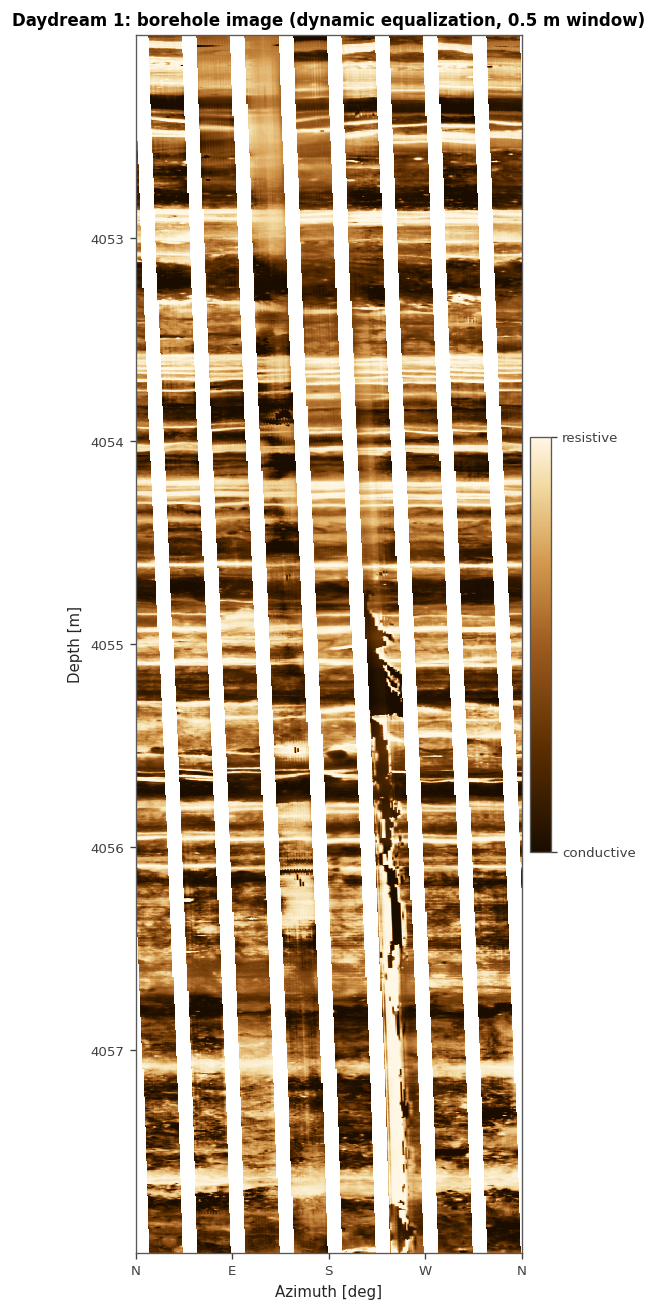

In [10]:
pp.fmi_panel(data, top=4052, bottom=4058, orient=True, equalize="dynamic");

## Pitfalls & parameter choices

- **Filter before you orient.** A processed FMI is huge (here 500,788 rows x 192
  buttons at 2.5 mm). Cut a working window with `filter_by_depth` (or pass
  `depth_range` to `fmi_panel`) first; orienting the full log burns memory
  and time on wall you are not interpreting.
- **Orientation needs navigation.** `orient_to_azimuth(reference="north")` requires
  `P1AZ`; `reference="highside"` requires `RB`. `read_fmi_dlis` loads these for you and
  interpolates them onto image depth. If your image arrives as bare arrays, build it
  with `BoreholeImageData.from_arrays` and attach the curves with `with_navigation`,
  or orientation raises.
- **Gaps are real, not missing.** Inter-pad wedges stay `NaN` on purpose. Do not
  in-fill them before dip picking - the empty azimuths are genuine no-coverage.
- **`n_azimuth` is a display grid, not resolution.** Choosing 360 vs 180 bins only sets
  how finely buttons are re-binned; it cannot create coverage the tool never recorded.
- **Static vs dynamic is a trade, not a ranking.** Static keeps absolute contrast;
  dynamic surfaces texture. Interpreters routinely view both - and note that a
  *processed dynamic* deliverable (like this file) cannot be turned back into a
  static display; request both products from the vendor.
- **`read_borehole_image_las` regroups flattened curves** (`FMPA_0..FMPA_23`); make sure
  the exporter used a consistent `PREFIX_index` naming or pass `channel_prefixes`.

## Recap

- An FMI records microresistivity **buttons on pads/flaps**, not compass-referenced
  pixels; the raw strip is not yet an image.
- `BoreholeImageData` holds depth, the 2D button array, and which columns belong to which
  array - everything `orient_to_azimuth` needs.
- **Orientation** (`orient_to_azimuth`, using `P1AZ` + fixed offsets) is what turns the
  strip into a compass-referenced image where a dipping bed reads as a **sinusoid**.
- **Equalization** (`plot_fmi(equalize="static")` or `"dynamic"`) tunes contrast;
  **coverage** (`azimuthal_coverage`) tells you how much of the wall was actually seen.
- `plot_fmi` and `fmi_panel` render the result in one call.

## Try it yourself

> **Exercise 1.** Orient the 4052-4058 m window with `n_azimuth=360`
> (`plot_fmi(orient_to_azimuth(data.filter_by_depth(4052, 4058), n_azimuth=360))`) and
> study the dark (conductive) near-vertical trace at roughly SW-WSW azimuth
> (about 220-250 degrees), and look for a fainter partner about 180 degrees away. It does not cross the image as a
> sinusoid, and its azimuth drifts with depth beside a pad edge. Is it a feature of
> the borehole wall or of the tool? (Hint: drilling-induced tensile fractures form
> 180 degrees apart along the maximum horizontal stress azimuth and keep that
> azimuth with depth; a trace that turns with the pads, as the gaps between them
> do, is tied to the tool; a steeply dipping natural fracture would trace a
> high-amplitude sinusoid.)
>
> **Exercise 2.** Re-orient the 2900-2910 m window with `reference="highside"`
> (uses `RB`) and compare against the north-referenced image. In a near-vertical
> hole (check `DEVI` in the navigation table), why is the highside reference less stable?
>
> **Exercise 3.** Re-run `orient_to_azimuth` with `n_azimuth=90` and again with `360`.
> Compare `azimuthal_coverage` - does more bins buy more coverage? Why not?

## What's next

Continue with **17_visualization_masterclass.ipynb**, where `fmi_panel` takes its
place alongside the full petrophys plotting gallery: template log viewers, triple combo,
the crossplot family, and specialist NMR/flow-unit panels.